In [1]:
!pip install opencv-python
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

Saving shape.png to shape.png


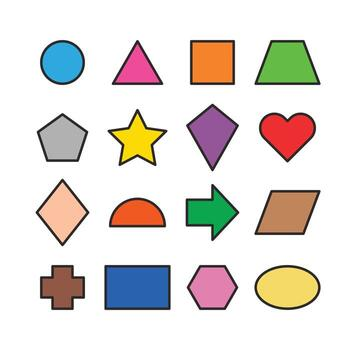

In [4]:
from google.colab import files

uploaded = files.upload()

image = cv2.imread("shape.png")
cv2_imshow(image)

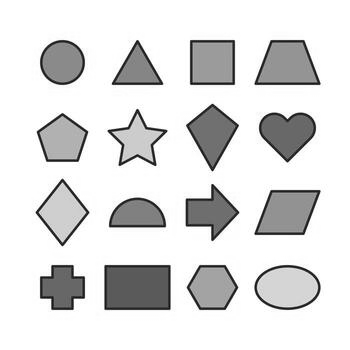

In [5]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2_imshow(gray)

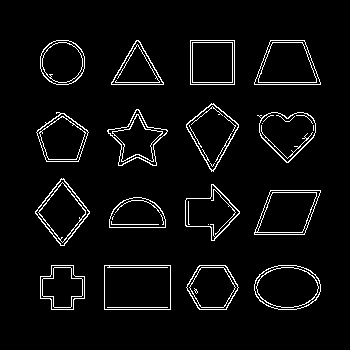

In [7]:
edges = cv2.Canny(gray, 30, 100)

cv2_imshow(edges)

In [8]:
contours, _ = cv2.findContours(
    edges,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

In [9]:
for contour in contours:

    area = cv2.contourArea(contour)

    if area < 500:
        continue   # ignore small noise

    perimeter = cv2.arcLength(contour, True)

    approx = cv2.approxPolyDP(
        contour,
        0.04 * perimeter,
        True
    )

    vertices = len(approx)

    x, y, w, h = cv2.boundingRect(approx)
    aspect_ratio = float(w) / h

    if vertices == 3:
        shape = "Triangle"

    elif vertices == 4:
        if 0.9 <= aspect_ratio <= 1.1:
            shape = "Square"
        else:
            shape = "Rectangle"

    elif vertices == 5:
        shape = "Pentagon"

    elif vertices == 6:
        shape = "Hexagon"

    else:
        circularity = 4 * np.pi * area / (perimeter * perimeter)

        if circularity > 0.8:
            shape = "Circle"

        elif aspect_ratio > 1.2 or aspect_ratio < 0.8:
            shape = "Oval"

        else:
            shape = "Polygon"

    cv2.drawContours(
        image,
        [approx],
        -1,
        (0, 255, 0),
        3
    )

    cv2.putText(
        image,
        shape,
        (x, y - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

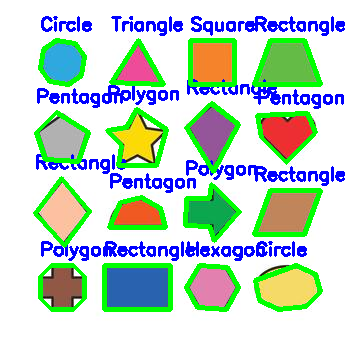

In [10]:
cv2_imshow(image)